In [1]:
import pandas as pd
df = pd.read_csv("mangga_v1.csv")
df

,berat_g,panjang_cm,diameter_cm,kadar_gula_brix,varietas,asal_kota,tingkat_kematangan,grade_kualitas
0,293.9,12.2,7.4,12.2,Harum Manis,Probolinggo,Mengkal,Standar
1,402.6,10.7,7.4,12.1,Harum Manis,Indramayu,Mengkal,Standar
2,272.2,11.0,7.3,9.2,Manalagi,Indramayu,Mentah,Afkir
3,357.3,14.4,7.4,13.8,Harum Manis,Probolinggo,Mengkal,Standar
4,313.6,14.9,8.9,20.8,Golek,Indramayu,Terlalu Matang,Premium
...,...,...,...,...,...,...,...,...
895,260.6,11.3,7.7,7.0,Manalagi,Majalengka,Mentah,Afkir
896,429.4,13.2,8.3,13.1,Harum Manis,Probolinggo,Mengkal,Standar
897,370.4,16.1,7.0,17.4,Golek,Probolinggo,Matang,Premium
898,249.9,13.2,8.1,14.3,Harum Manis,Indramayu,Matang,Premium


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   berat_g             890 non-null    float64
 1   panjang_cm          892 non-null    float64
 2   diameter_cm         891 non-null    float64
 3   kadar_gula_brix     888 non-null    float64
 4   varietas            891 non-null    str    
 5   asal_kota           892 non-null    str    
 6   tingkat_kematangan  890 non-null    str    
 7   grade_kualitas      888 non-null    str    
dtypes: float64(4), str(4)
memory usage: 85.1 KB


In [3]:
df.isnull().sum()


berat_g               10
panjang_cm             8
diameter_cm            9
kadar_gula_brix       12
varietas               9
asal_kota              8
tingkat_kematangan    10
grade_kualitas        12
dtype: int64

In [4]:
df.shape


(900, 8)

In [5]:
df.columns

Index(['berat_g', 'panjang_cm', 'diameter_cm', 'kadar_gula_brix', 'varietas',
       'asal_kota', 'tingkat_kematangan', 'grade_kualitas'],
      dtype='str')

In [6]:
df.dtypes

berat_g               float64
panjang_cm            float64
diameter_cm           float64
kadar_gula_brix       float64
varietas                  str
asal_kota                 str
tingkat_kematangan        str
grade_kualitas            str
dtype: object

In [7]:
print(df.duplicated().sum())

9


In [8]:
df = df.drop_duplicates()

In [9]:
df.shape

(891, 8)

In [10]:
df = df.dropna(subset=["grade_kualitas"])

In [11]:
df.isna().sum()

berat_g               10
panjang_cm             8
diameter_cm            9
kadar_gula_brix       12
varietas               9
asal_kota              8
tingkat_kematangan    10
grade_kualitas         0
dtype: int64

In [12]:
df.shape

(879, 8)

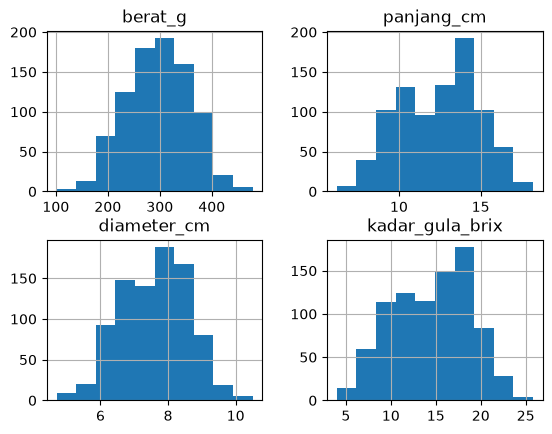

In [13]:
_= df.hist()

In [14]:
print(abs(df["berat_g"].skew()))

0.11600936683841043


In [15]:
print(abs(df["panjang_cm"].skew()))

0.15724222612467384


In [16]:
print(abs(df["diameter_cm"].skew()))

0.07460490173136104


In [17]:
print(abs(df["kadar_gula_brix"].skew()))

0.1461560969462655


In [18]:
df["berat_g"] = df["berat_g"].fillna(df["berat_g"].mean())

In [19]:
df.isna().sum()

berat_g                0
panjang_cm             8
diameter_cm            9
kadar_gula_brix       12
varietas               9
asal_kota              8
tingkat_kematangan    10
grade_kualitas         0
dtype: int64

In [20]:
df["panjang_cm"] = df["panjang_cm"].fillna(df["panjang_cm"].mean())
df["diameter_cm"] = df["diameter_cm"].fillna(df["diameter_cm"].mean())
df["kadar_gula_brix"] = df["kadar_gula_brix"].fillna(df["kadar_gula_brix"].mean())

In [21]:
df.isna().sum()

berat_g                0
panjang_cm             0
diameter_cm            0
kadar_gula_brix        0
varietas               9
asal_kota              8
tingkat_kematangan    10
grade_kualitas         0
dtype: int64

In [22]:
df["varietas"].value_counts()

varietas
Harum Manis     309
Manalagi        210
Golek           197
Gedong Gincu    154
Name: count, dtype: int64

In [23]:
df["asal_kota"].value_counts()

asal_kota
Indramayu      240
Probolinggo    219
Pasuruan       218
Majalengka     194
Name: count, dtype: int64

In [24]:
df["tingkat_kematangan"].value_counts()

tingkat_kematangan
Matang            344
Mengkal           251
Mentah            149
Terlalu Matang    125
Name: count, dtype: int64

In [25]:
df["grade_kualitas"].value_counts()

grade_kualitas
Premium    384
Standar    285
Afkir      210
Name: count, dtype: int64

In [26]:
df["varietas"] = df["varietas"].fillna(df["varietas"].mode()[0])
df["asal_kota"] = df["asal_kota"].fillna(df["asal_kota"].mode()[0])
df["tingkat_kematangan"] = df["tingkat_kematangan"].fillna(df["tingkat_kematangan"].mode()[0])


In [27]:
df.isna().sum()

berat_g               0
panjang_cm            0
diameter_cm           0
kadar_gula_brix       0
varietas              0
asal_kota             0
tingkat_kematangan    0
grade_kualitas        0
dtype: int64

In [28]:
df.corr(numeric_only=True)

,berat_g,panjang_cm,diameter_cm,kadar_gula_brix
berat_g,1.000000,0.615601,0.528834,0.007888
panjang_cm,0.615601,1.000000,0.666106,0.046462
diameter_cm,0.528834,0.666106,1.000000,0.065002
kadar_gula_brix,0.007888,0.046462,0.065002,1.000000


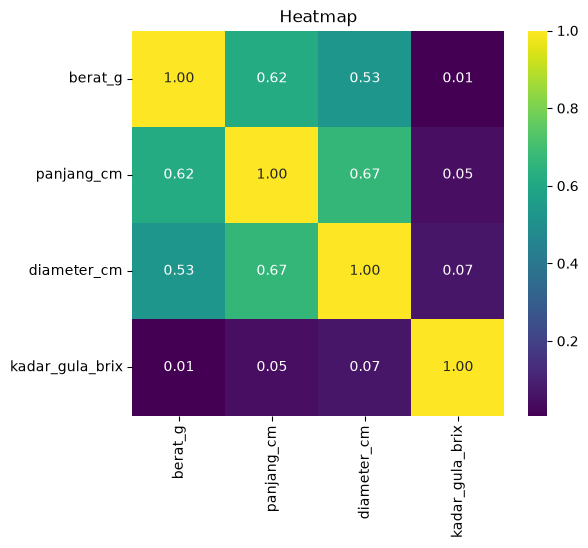

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = df.corr(numeric_only=True)

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap="viridis", fmt=".2f")
plt.title("Heatmap")
plt.show()


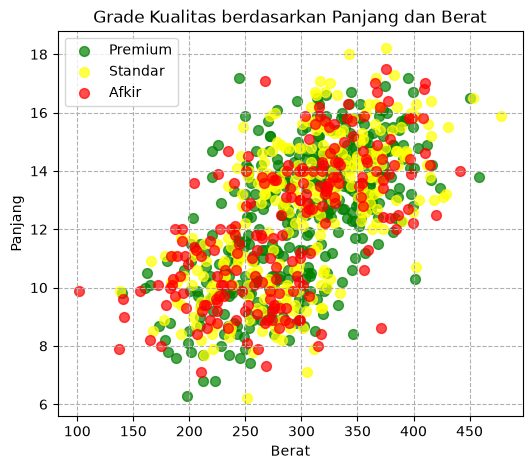

In [30]:
import matplotlib.pyplot as plt

premium = df[df["grade_kualitas"] == "Premium"]
standar = df[df["grade_kualitas"] == "Standar"]
afkir = df[df["grade_kualitas"] == "Afkir"]

plt.figure(figsize=(6,5))
plt.scatter(premium["berat_g"], premium["panjang_cm"], s=50, alpha=0.7, color="green",label="Premium")
plt.scatter(standar["berat_g"], standar["panjang_cm"], s=50, alpha=0.7, color="yellow",label="Standar")
plt.scatter(afkir["berat_g"], afkir["panjang_cm"], s=50, alpha=0.7, color="red",label="Afkir")
plt.title("Grade Kualitas berdasarkan Panjang dan Berat")
plt.xlabel("Berat")
plt.ylabel("Panjang")
plt.grid(True, linestyle="--")
plt.legend()
plt.show()



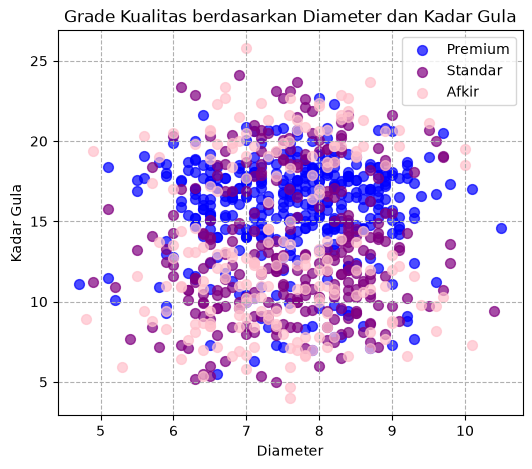

In [31]:
plt.figure(figsize=(6,5))
plt.scatter(premium["diameter_cm"], premium["kadar_gula_brix"], s=50, alpha=0.7, color="blue",label="Premium")
plt.scatter(standar["diameter_cm"], standar["kadar_gula_brix"], s=50, alpha=0.7, color="purple",label="Standar")
plt.scatter(afkir["diameter_cm"], afkir["kadar_gula_brix"], s=50, alpha=0.7, color="pink",label="Afkir")
plt.title("Grade Kualitas berdasarkan Diameter dan Kadar Gula")
plt.xlabel("Diameter")
plt.ylabel("Kadar Gula")
plt.grid(True, linestyle="--")
plt.legend()
plt.show()

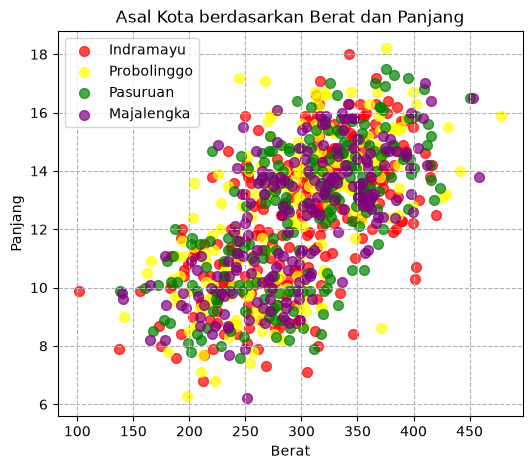

In [32]:
import matplotlib.pyplot as plt

indramayu = df[df["asal_kota"] == "Indramayu"]
probolinggo = df[df["asal_kota"] == "Probolinggo"]
pasuruan = df[df["asal_kota"] == "Pasuruan"]
majalengka = df[df["asal_kota"] == "Majalengka"]

plt.figure(figsize=(6,5))
plt.scatter(indramayu["berat_g"], indramayu["panjang_cm"], s=50, alpha=0.7, color="red",label="Indramayu")
plt.scatter(probolinggo["berat_g"], probolinggo["panjang_cm"], s=50, alpha=0.7, color="yellow",label="Probolinggo")
plt.scatter(pasuruan["berat_g"], pasuruan["panjang_cm"], s=50, alpha=0.7, color="green",label="Pasuruan")
plt.scatter(majalengka["berat_g"], majalengka["panjang_cm"], s=50, alpha=0.7, color="purple", label="Majalengka")
plt.title("Asal Kota berdasarkan Berat dan Panjang")
plt.xlabel("Berat")
plt.ylabel("Panjang")
plt.grid(True, linestyle="--")
plt.legend()
plt.show()

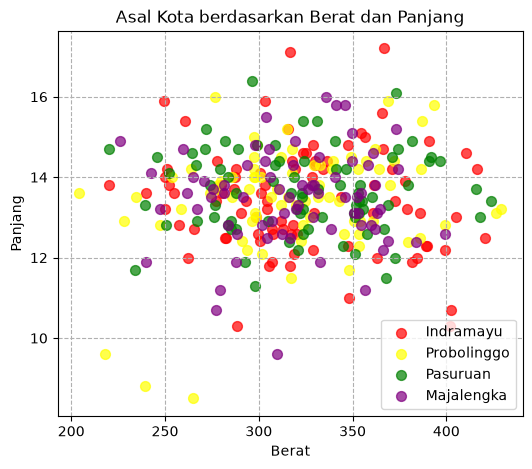

In [33]:
indramayu = df[(df["asal_kota"] == "Indramayu") & (df["varietas"]=="Harum Manis")]
probolinggo = df[(df["asal_kota"] == "Probolinggo") & (df["varietas"]=="Harum Manis")]
pasuruan = df[(df["asal_kota"] == "Pasuruan") & (df["varietas"]=="Harum Manis")]
majalengka = df[(df["asal_kota"] == "Majalengka") & (df["varietas"]=="Harum Manis")]

plt.figure(figsize=(6,5))
plt.scatter(indramayu["berat_g"], indramayu["panjang_cm"], s=50, alpha=0.7, color="red",label="Indramayu")
plt.scatter(probolinggo["berat_g"], probolinggo["panjang_cm"], s=50, alpha=0.7, color="yellow",label="Probolinggo")
plt.scatter(pasuruan["berat_g"], pasuruan["panjang_cm"], s=50, alpha=0.7, color="green",label="Pasuruan")
plt.scatter(majalengka["berat_g"], majalengka["panjang_cm"], s=50, alpha=0.7, color="purple", label="Majalengka")
plt.title("Asal Kota berdasarkan Berat dan Panjang")
plt.xlabel("Berat")
plt.ylabel("Panjang")
plt.grid(True, linestyle="--")
plt.legend()
plt.show()

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


X = df[["berat_g", "panjang_cm", "diameter_cm", "kadar_gula_brix", "varietas", "asal_kota", "tingkat_kematangan"]]
y = df["grade_kualitas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_columns = ["berat_g","panjang_cm","diameter_cm","kadar_gula_brix"]
categorical_columns = ["varietas", "asal_kota"]
ordinal_columns = ["tingkat_kematangan"]

tingkat_kematangan_order = ["Mentah", "Mengkal", "Matang", "Terlalu Matang"]
ordinal_order = [tingkat_kematangan_order]

preprocessing = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), numeric_columns),
        ("ohe", OneHotEncoder(), categorical_columns),
        ("oe", OrdinalEncoder(categories=ordinal_order), ordinal_columns)
    ]
)
model = Pipeline(
    steps=[
        ("preprocessing", preprocessing),
        ("model", LogisticRegression())
    ]
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy :", accuracy_score(y_test, y_pred))
print("\nClassification Report :\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix :\n", confusion_matrix(y_test, y_pred))


scores = cross_val_score(model, X_train, y_train, cv=5)
print("Scores : ", scores)
print("Mean Scores : ", scores.mean())

Accuracy : 0.44886363636363635

Classification Report :
               precision    recall  f1-score   support

       Afkir       0.20      0.02      0.04        42
     Premium       0.51      0.78      0.62        77
     Standar       0.34      0.32      0.33        57

    accuracy                           0.45       176
   macro avg       0.35      0.37      0.33       176
weighted avg       0.38      0.45      0.39       176


Confusion Matrix :
 [[ 1 22 19]
 [ 1 60 16]
 [ 3 36 18]]
Scores :  [0.4964539  0.5035461  0.5177305  0.46428571 0.49285714]
Mean Scores :  0.49497467071935153
